In [10]:
import pandas as pd

df = pd.read_csv("data/DATASET-Raw_data_clean.csv")
print(df.shape)
print(df.head())
print(df.isna().sum()[df.isna().sum() > 0])

(2992, 42)
   birth_year  gender  ses  ethnicity  father_edu_years  mother_edu_years  \
0        2001       1    4          6              25.0              25.0   
1        1999       1    2          1               NaN               NaN   
2        2002       1    5          6              16.0              16.0   
3        2001       2    5          6              20.0              16.0   
4        1999       1    4          5               NaN               NaN   

   life_satisfaction  happy_yesterday  laugh_yesterday  learn_yesterday  ...  \
0                  7                5                5                5  ...   
1                  8                4                8                3  ...   
2                 10                9               10                7  ...   
3                 10                8               10               10  ...   
4                  8                6                7                3  ...   

   gad7  phq1  phq2  phq3  phq4  phq5  phq6  

In [11]:
print(df["phq9"].value_counts().sort_index())
print((df["phq9"] > 0).sum())
print((df["phq9"] > 0).mean())

phq9
0    2165
1     510
2     158
3     159
Name: count, dtype: int64
827
0.27640374331550804


In [12]:
phq_cols = [f"phq{i}" for i in range(1, 10)]
df["phq_total"] = df[phq_cols].sum(axis=1)

def severity_band(total):
    if total <= 4:
        return "Minimal"
    elif total <= 9:
        return "Mild"
    elif total <= 14:
        return "Moderate"
    elif total <= 19:
        return "Moderately severe"
    else:
        return "Severe"

df["phq_band"] = df["phq_total"].apply(severity_band)
print(df["phq_band"].value_counts())

phq_band
Mild                 936
Minimal              861
Moderate             609
Moderately severe    358
Severe               228
Name: count, dtype: int64


In [13]:
print(df.describe().loc[["min", "max"]].T)
print(df[df["birth_year"] > 2006]["birth_year"].value_counts())
print((df["birth_year"] < 1990).sum())
print((df["father_edu_years"] > 25).sum())
print((df["mother_edu_years"] > 25).sum())
print(df.duplicated().sum())

                        min     max
birth_year           1973.0  2022.0
gender                  1.0     2.0
ses                     1.0     6.0
ethnicity               1.0     6.0
father_edu_years        0.0    43.0
mother_edu_years        0.0    51.0
life_satisfaction       0.0    10.0
happy_yesterday         0.0    10.0
laugh_yesterday         0.0    10.0
learn_yesterday         0.0    10.0
enjoy_yesterday         0.0    10.0
worried_yesterday       0.0    10.0
depressed_yesterday     0.0    10.0
angry_yesterday         0.0    10.0
stress_yesterday        0.0    10.0
lonely_yesterday        0.0    10.0
pss1                    0.0     4.0
pss2                    0.0     4.0
pss3                    0.0     4.0
pss4                    0.0     4.0
pss5                    0.0     4.0
pss6                    0.0     4.0
pss7                    0.0     4.0
pss8                    0.0     4.0
pss9                    0.0     4.0
pss10                   0.0     4.0
gad1                    0.0 

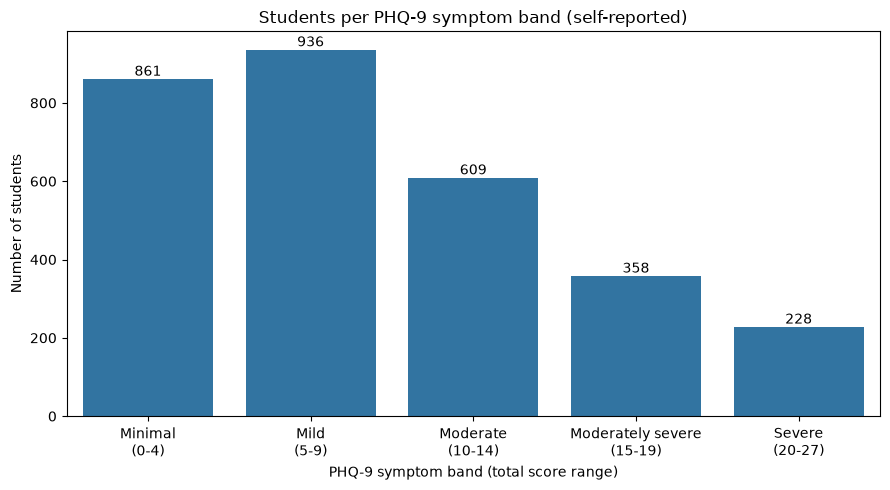

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

band_labels = {
    "Minimal": "Minimal\n(0-4)",
    "Mild": "Mild\n(5-9)",
    "Moderate": "Moderate\n(10-14)",
    "Moderately severe": "Moderately severe\n(15-19)",
    "Severe": "Severe\n(20-27)",
}
labelled_band = df["phq_band"].map(band_labels)

plt.figure(figsize=(9, 5))
ax = sns.countplot(x=labelled_band, order=list(band_labels.values()))
ax.bar_label(ax.containers[0])
plt.title("Students per PHQ-9 symptom band (self-reported)")
plt.xlabel("PHQ-9 symptom band (total score range)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig("figures/phq_bands.png", dpi=150)
plt.show()

In [15]:
df["crisis"] = df["phq9"] > 0
df["high_total"] = df["phq_total"] >= 15
print(pd.crosstab(df["crisis"], df["high_total"], margins=True))

high_total  False  True   All
crisis                       
False        2009   156  2165
True          397   430   827
All          2406   586  2992


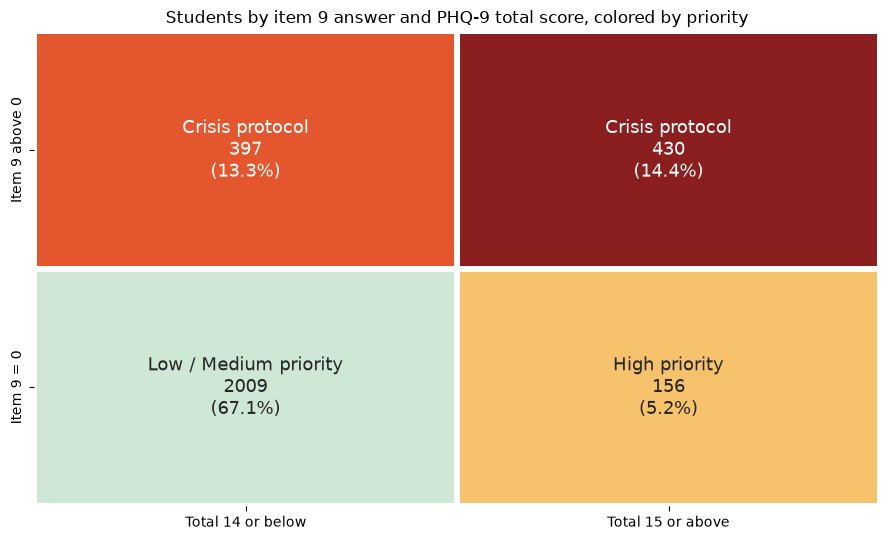

In [16]:
import numpy as np
from matplotlib.colors import ListedColormap

counts = pd.crosstab(df["crisis"], df["high_total"]).sort_index(ascending=False)
counts.index = ["Item 9 above 0", "Item 9 = 0"]
counts.columns = ["Total 14 or below", "Total 15 or above"]

rank = np.array([[3, 4],
                 [1, 2]])

names = [["Crisis protocol", "Crisis protocol"],
         ["Low / Medium priority", "High priority"]]

labels = np.array([[f"{names[r][c]}\n{counts.iloc[r, c]}\n({counts.iloc[r, c] / len(df):.1%})"
                    for c in range(2)] for r in range(2)])

priority_colors = ListedColormap(["#cfe8d5", "#f6c26b", "#e4572e", "#8b1e1e"])

plt.figure(figsize=(9, 5.5))
sns.heatmap(rank, annot=labels, fmt="", cmap=priority_colors, vmin=0.5, vmax=4.5,
            cbar=False, linewidths=3, linecolor="white",
            xticklabels=counts.columns, yticklabels=counts.index,
            annot_kws={"size": 13})
plt.title("Students by item 9 answer and PHQ-9 total score, colored by priority")
plt.tight_layout()
plt.savefig("figures/crisis_by_total.png", dpi=150)
plt.show()

In [17]:
print(pd.crosstab(df["phq9"], df["high_total"], margins=True))

high_total  False  True   All
phq9                         
0            2009   156  2165
1             323   187   510
2              49   109   158
3              25   134   159
All          2406   586  2992


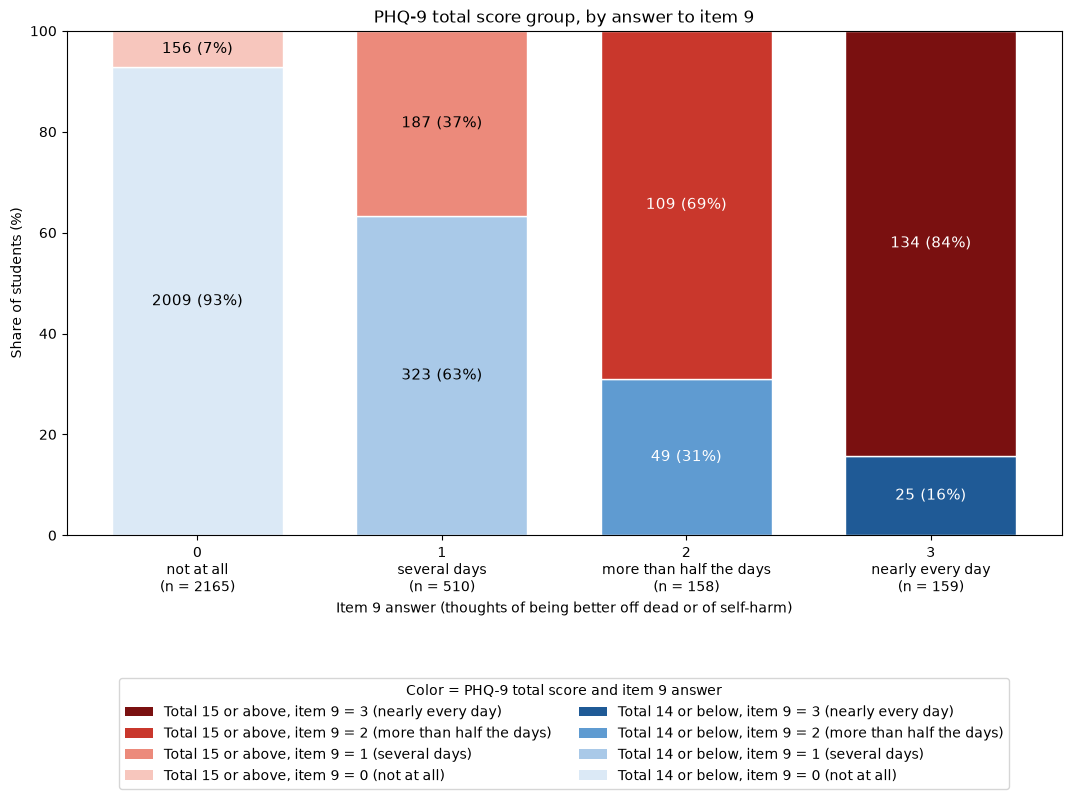

In [18]:
from matplotlib.patches import Patch

answer_words = {0: "not at all", 1: "several days",
                2: "more than half the days", 3: "nearly every day"}

tbl = pd.crosstab(df["phq9"], df["high_total"])
tbl.columns = ["low", "high"]
pct = tbl.div(tbl.sum(axis=1), axis=0) * 100

blues = ["#dbe9f6", "#a9c9e8", "#5f9bd1", "#1f5a96"]
reds = ["#f7c6bd", "#ec8a7b", "#c9372c", "#7a1010"]
text_colors = ["black", "black", "white", "white"]

fig, ax = plt.subplots(figsize=(11, 8.5))

for answer in tbl.index:
    low_pct = pct.loc[answer, "low"]
    high_pct = pct.loc[answer, "high"]
    ax.bar(answer, low_pct, color=blues[answer], edgecolor="white", width=0.7)
    ax.bar(answer, high_pct, bottom=low_pct, color=reds[answer], edgecolor="white", width=0.7)
    ax.text(answer, low_pct / 2, f"{tbl.loc[answer, 'low']} ({low_pct:.0f}%)",
            ha="center", va="center", color=text_colors[answer], fontsize=11)
    ax.text(answer, low_pct + high_pct / 2, f"{tbl.loc[answer, 'high']} ({high_pct:.0f}%)",
            ha="center", va="center", color=text_colors[answer], fontsize=11)

handles = [Patch(facecolor=reds[a], label=f"Total 15 or above, item 9 = {a} ({answer_words[a]})")
           for a in [3, 2, 1, 0]]
handles += [Patch(facecolor=blues[a], label=f"Total 14 or below, item 9 = {a} ({answer_words[a]})")
            for a in [3, 2, 1, 0]]
ax.legend(handles=handles, title="Color = PHQ-9 total score and item 9 answer",
          loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, fontsize=10)

ax.set_xticks(list(tbl.index))
ax.set_xticklabels([f"{a}\n{answer_words[a]}\n(n = {tbl.loc[a].sum()})" for a in tbl.index])
ax.set_ylim(0, 100)
ax.set_xlabel("Item 9 answer (thoughts of being better off dead or of self-harm)")
ax.set_ylabel("Share of students (%)")
ax.set_title("PHQ-9 total score group, by answer to item 9")
plt.tight_layout()
plt.savefig("figures/item9_by_total.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
def assign_level(item9, total):
    if item9 == 3:
        return 1
    elif item9 == 2:
        return 2
    elif item9 == 1 and total >= 15:
        return 3
    elif item9 == 1:
        return 4
    elif total >= 15:
        return 5
    else:
        return 6

print(assign_level(3, 5), assign_level(2, 10), assign_level(1, 20),
      assign_level(1, 8), assign_level(0, 18), assign_level(0, 6))

df["level"] = [assign_level(a, t) for a, t in zip(df["phq9"], df["phq_total"])]
print(df["level"].value_counts().sort_index())

1 2 3 4 5 6
level
1     159
2     158
3     187
4     323
5     156
6    2009
Name: count, dtype: int64


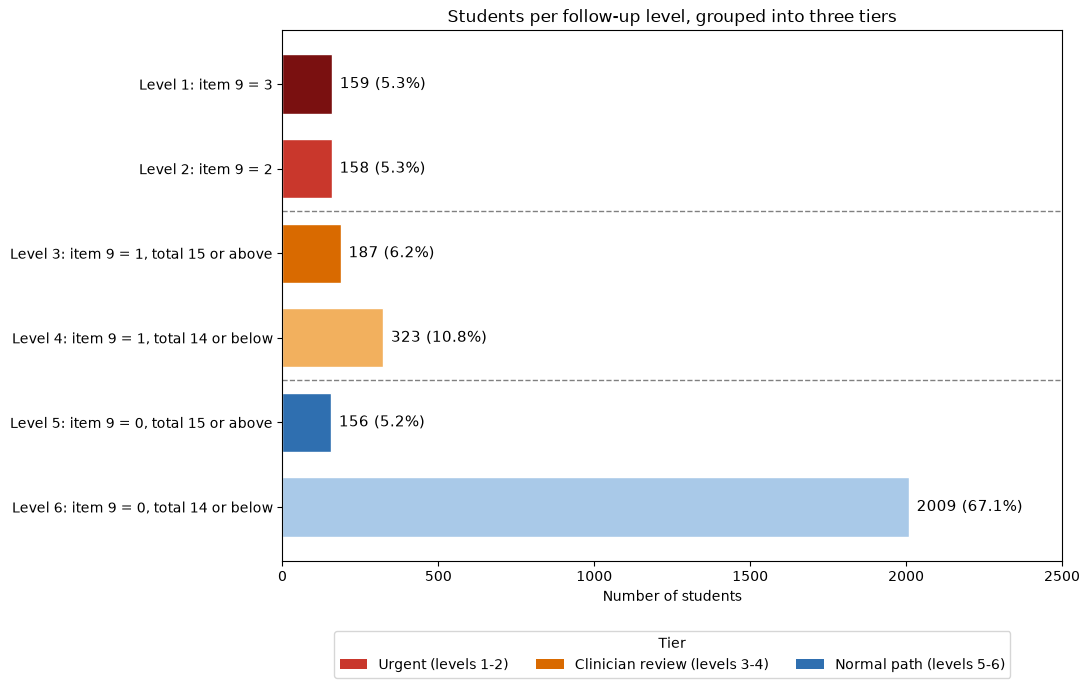

In [20]:
level_counts = df["level"].value_counts().sort_index()

level_labels = {
    1: "Level 1: item 9 = 3",
    2: "Level 2: item 9 = 2",
    3: "Level 3: item 9 = 1, total 15 or above",
    4: "Level 4: item 9 = 1, total 14 or below",
    5: "Level 5: item 9 = 0, total 15 or above",
    6: "Level 6: item 9 = 0, total 14 or below",
}
level_colors = {1: "#7a1010", 2: "#c9372c", 3: "#d96a00", 4: "#f2b05e",
                5: "#2f6fb0", 6: "#a9c9e8"}

fig, ax = plt.subplots(figsize=(11, 7))

for pos, level in enumerate(level_counts.index):
    n = level_counts[level]
    ax.barh(pos, n, color=level_colors[level], edgecolor="white", height=0.7)
    ax.text(n + 25, pos, f"{n} ({n / len(df):.1%})", va="center", fontsize=11)

ax.set_yticks(range(len(level_counts)))
ax.set_yticklabels([level_labels[level] for level in level_counts.index])
ax.invert_yaxis()
ax.axhline(1.5, color="gray", linestyle="--", linewidth=1)
ax.axhline(3.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0, 2500)
ax.set_xlabel("Number of students")
ax.set_title("Students per follow-up level, grouped into three tiers")

tier_handles = [
    Patch(facecolor="#c9372c", label="Urgent (levels 1-2)"),
    Patch(facecolor="#d96a00", label="Clinician review (levels 3-4)"),
    Patch(facecolor="#2f6fb0", label="Normal path (levels 5-6)"),
]
ax.legend(handles=tier_handles, title="Tier", loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=10)

plt.tight_layout()
plt.savefig("figures/levels_and_tiers.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
protocols = {
    "A": {
        "name": "Immediate safety follow-up",
        "crisis": True,
        "text": """This student answered 2 or 3 on PHQ-9 item 9 (thoughts of being better off dead or of self-harm on more than half the days or nearly every day). No score is shown. A follow-up conversation is recommended.
1. Contact the student: same day for level 1, within 24-48 hours for level 2.
2. A trained counselor carries out a structured suicide risk assessment (for example the C-SSRS) and, where possible, consults a second trained colleague before deciding on the level of care.
3. If the student shows immediate danger (a plan, intent, or access to means): do not leave them alone, remove means if it is safe to do so, and call emergency services [local emergency number].
4. Contact the parent or guardian according to institutional policy, and advise securing medications and other dangerous items.
5. Complete a safety plan with the student: warning signs, coping strategies, supports, crisis line numbers.
6. Refer to community mental health services with 24-hour access if needed, and obtain consent to share information with the providers.
7. Document every contact and decision. Follow up within one week and again at one month.
The counselor decides. This tool does not diagnose.""",
    },
    "B": {
        "name": "Clinician review",
        "crisis": True,
        "text": """This student answered 1 on PHQ-9 item 9 (such thoughts on several days). No score is shown. A follow-up conversation is recommended.
1. A counselor reviews and contacts the student: within 3 days for level 3 (PHQ-9 total 15 or higher), within 4 days for level 4 (total 14 or lower). The order is a sorting aid, not a difference in risk.
2. In the conversation, ask directly about suicidal thoughts and carry out a structured screening (for example the C-SSRS screener).
3. If the screening suggests higher risk, move to Path A at once.
4. If not, agree a safety plan where needed, share resources and counseling options, and involve the parent or guardian according to policy.
5. Document the contact and the plan. Check in again within 2 weeks.
The counselor decides. This tool does not diagnose.""",
    },
    "C": {
        "name": "Routine support",
        "crisis": False,
        "text": """The student answered 0 on PHQ-9 item 9. This is not a crisis path, and a score may be shown.
1. Level 5 (PHQ-9 total 15 or higher): offer a check-in conversation and information about support services.
2. Level 6 (total 14 or lower): routine support. Share wellbeing resources. Students are listed by total, highest first.
3. An answer of 0 does not rule out risk. If a concern arises later from the student or anyone else, use Path A or B at any time.
The counselor decides. This tool does not diagnose.""",
    },
}

level_info = {
    1: {"protocol": "A", "label": "Same day"},
    2: {"protocol": "A", "label": "Within 24-48 hours"},
    3: {"protocol": "B", "label": "Priority review"},
    4: {"protocol": "B", "label": "Scheduled review"},
    5: {"protocol": "C", "label": "Check-in offered"},
    6: {"protocol": "C", "label": "Routine"},
}

In [22]:
phq_names = {
    1: "Little interest or pleasure in doing things",
    2: "Feeling down, depressed or hopeless",
    3: "Trouble with sleep",
    4: "Feeling tired or having little energy",
    5: "Poor appetite or overeating",
    6: "Feeling bad about yourself or like a failure",
    7: "Trouble concentrating",
    8: "Moving or speaking very slowly, or being restless",
    9: "Thoughts of being better off dead or of self-harm",
}

def get_reasons(row):
    reasons = []
    if row["phq9"] >= 1:
        reasons.append(phq_names[9])
    for i in range(1, 9):
        if row[f"phq{i}"] >= 2:
            reasons.append(phq_names[i])
    return reasons

df["reasons"] = df.apply(get_reasons, axis=1)

In [23]:
df[["phq9", "phq_total", "level", "reasons"]].head(10)

,phq9,phq_total,level,reasons
0,0,4,6,[Poor appetite or overeating]
1,0,11,6,"[Little interest or pleasure in doing things, ..."
2,0,8,6,"[Feeling tired or having little energy, Poor a..."
3,0,8,6,"[Little interest or pleasure in doing things, ..."
4,3,12,1,[Thoughts of being better off dead or of self-...
5,0,3,6,[]
6,1,15,3,[Thoughts of being better off dead or of self-...
7,0,2,6,[]
8,0,10,6,"[Little interest or pleasure in doing things, ..."
9,0,0,6,[]


In [24]:
df["phq10_plus"] = (df["phq_total"] >= 10).astype(int)

print(df["phq10_plus"].value_counts())
print(df["phq10_plus"].value_counts(normalize=True))

phq10_plus
0    1797
1    1195
Name: count, dtype: int64
phq10_plus
0    0.600602
1    0.399398
Name: proportion, dtype: float64


In [26]:
feature_cols = (
    ["life_satisfaction"]
    + [f"{name}_yesterday" for name in ["happy", "laugh", "learn", "enjoy", "worried", "angry", "stress", "lonely"]]
    + [f"pss{i}" for i in range(1, 11)]
    + [f"gad{i}" for i in range(1, 8)]
)

X = df[feature_cols]
y = df["phq10_plus"]
groups = df[["gender", "ses", "ethnicity"]]

print(len(feature_cols))
print(X.shape, y.shape)
print(X.isna().sum().sum())
print(X.dtypes.unique())

26
(2992, 26) (2992,)
0
[dtype('int64')]


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, groups_train, groups_test = train_test_split(
    X, y, groups, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(2393, 26) (599, 26)
0.3994985374007522 0.3989983305509182


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred))
print(rf.score(X_train, y_train), rf.score(X_test, y_test))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       360
           1       0.78      0.68      0.73       239

    accuracy                           0.80       599
   macro avg       0.79      0.78      0.78       599
weighted avg       0.80      0.80      0.80       599

1.0 0.7979966611018364


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test)

print(classification_report(y_test, y_pred_lr))
print(logreg.score(X_train, y_train), logreg.score(X_test, y_test))

              precision    recall  f1-score   support

           0       0.82      0.86      0.84       360
           1       0.78      0.71      0.74       239

    accuracy                           0.80       599
   macro avg       0.80      0.79      0.79       599
weighted avg       0.80      0.80      0.80       599

0.8340994567488508 0.8013355592654424


In [30]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "recall", "precision", "f1"]

for name, model in [("Random forest", rf), ("Logistic regression", logreg)]:
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    print(name)
    for metric in scoring:
        values = scores["test_" + metric]
        print(f"  {metric}: {values.mean():.3f} (+/- {values.std():.3f})")

Random forest
  accuracy: 0.822 (+/- 0.015)
  recall: 0.757 (+/- 0.018)
  precision: 0.788 (+/- 0.025)
  f1: 0.772 (+/- 0.017)
Logistic regression
  accuracy: 0.823 (+/- 0.020)
  recall: 0.742 (+/- 0.023)
  precision: 0.802 (+/- 0.030)
  f1: 0.770 (+/- 0.025)


life_satisfaction   -0.328255
happy_yesterday     -0.238682
learn_yesterday     -0.190561
enjoy_yesterday     -0.141534
pss9                -0.119442
pss8                -0.107477
pss5                -0.099410
worried_yesterday   -0.051585
pss3                -0.026193
stress_yesterday     0.005344
pss7                 0.006329
pss4                 0.011739
pss1                 0.030658
angry_yesterday      0.047842
gad2                 0.098534
lonely_yesterday     0.147796
gad1                 0.200110
laugh_yesterday      0.245627
pss6                 0.253919
gad6                 0.261702
gad7                 0.268428
gad4                 0.319246
gad3                 0.319764
pss10                0.374589
pss2                 0.400168
gad5                 0.495042
dtype: float64


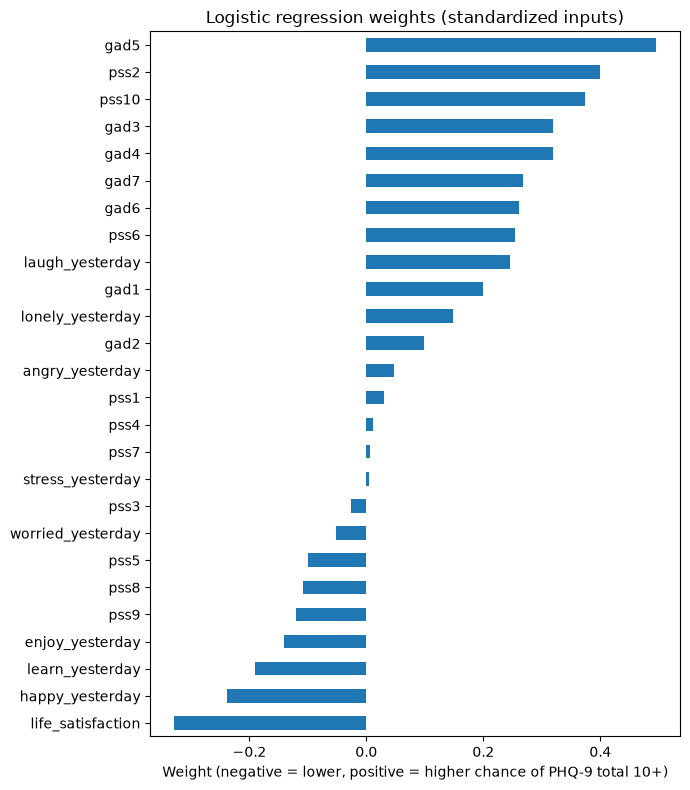

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

weights = pd.Series(
    logreg.named_steps["logisticregression"].coef_[0],
    index=X_train.columns,
).sort_values()

print(weights)

weights.plot(kind="barh", figsize=(7, 8))
plt.title("Logistic regression weights (standardized inputs)")
plt.xlabel("Weight (negative = lower, positive = higher chance of PHQ-9 total 10+)")
plt.tight_layout()
plt.savefig("figures/lr_weights.png", bbox_inches="tight")
plt.show()

In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

probs = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

for cutoff in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    pred = (probs >= cutoff).astype(int)
    print(
        f"cut-off {cutoff:.2f}: "
        f"recall {recall_score(y_train, pred):.3f}, "
        f"precision {precision_score(y_train, pred):.3f}, "
        f"invited {pred.mean():.1%}"
    )

cut-off 0.50: recall 0.742, precision 0.801, invited 37.0%
cut-off 0.45: recall 0.781, precision 0.782, invited 39.9%
cut-off 0.40: recall 0.814, precision 0.760, invited 42.8%
cut-off 0.35: recall 0.838, precision 0.740, invited 45.3%
cut-off 0.30: recall 0.870, precision 0.713, invited 48.8%
cut-off 0.25: recall 0.902, precision 0.686, invited 52.5%


In [33]:
from sklearn.metrics import confusion_matrix

cutoff = 0.35
test_probs = logreg.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= cutoff).astype(int)

print(classification_report(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.86      0.79      0.82       360
           1       0.72      0.81      0.76       239

    accuracy                           0.80       599
   macro avg       0.79      0.80      0.79       599
weighted avg       0.80      0.80      0.80       599

[[285  75]
 [ 46 193]]


In [34]:
check = groups_test.copy()
check["true"] = y_test
check["invited"] = test_pred
check["caught"] = (check["true"] == 1) & (check["invited"] == 1)

for col in ["gender", "ses", "ethnicity"]:
    summary = check.groupby(col).agg(
        students=("true", "size"),
        truly_10plus=("true", "sum"),
        caught=("caught", "sum"),
        invited_rate=("invited", "mean"),
    )
    summary["recall"] = summary["caught"] / summary["truly_10plus"]
    print(col)
    print(summary.round(2))
    print()

gender
        students  truly_10plus  caught  invited_rate  recall
gender                                                      
1            284           100      71          0.37    0.71
2            315           139     122          0.51    0.88

ses
     students  truly_10plus  caught  invited_rate  recall
ses                                                      
1          49            20      18          0.53    0.90
2         111            46      39          0.49    0.85
3         123            48      40          0.46    0.83
4         129            59      46          0.45    0.78
5         121            41      32          0.41    0.78
6          66            25      18          0.35    0.72

ethnicity
           students  truly_10plus  caught  invited_rate  recall
ethnicity                                                      
1                14             8       5          0.43    0.62
2                 2             2       2          1.00    1.00
3            

In [35]:
def recall_by_group(y_true, pred, groups_df):
    check = groups_df.copy()
    check["true"] = y_true
    check["invited"] = pred
    check["caught"] = (check["true"] == 1) & (check["invited"] == 1)

    for col in groups_df.columns:
        summary = check.groupby(col).agg(
            students=("true", "size"),
            truly_10plus=("true", "sum"),
            caught=("caught", "sum"),
            invited_rate=("invited", "mean"),
        )
        summary["recall"] = summary["caught"] / summary["truly_10plus"]
        print(col)
        print(summary.round(2))
        print()


cutoff = 0.35

print("TRAINING PART (cross-validated predictions)")
recall_by_group(y_train, (probs >= cutoff).astype(int), groups_train)

print("TEST PART (should match what you saw before)")
recall_by_group(y_test, test_pred, groups_test)

TRAINING PART (cross-validated predictions)
gender
        students  truly_10plus  caught  invited_rate  recall
gender                                                      
1           1123           376     289          0.36    0.77
2           1270           580     512          0.54    0.88

ses
     students  truly_10plus  caught  invited_rate  recall
ses                                                      
1         162            71      65          0.57    0.92
2         419           196     169          0.50    0.86
3         510           219     179          0.45    0.82
4         507           204     177          0.48    0.87
5         532           187     151          0.41    0.81
6         263            79      60          0.34    0.76

ethnicity
           students  truly_10plus  caught  invited_rate  recall
ethnicity                                                      
1                57            30      23          0.47    0.77
2                 4             3

In [36]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    {"model": logreg, "cutoff": cutoff, "features": feature_cols},
    "models/prescreen_model.joblib",
)

loaded = joblib.load("models/prescreen_model.joblib")
probs_again = loaded["model"].predict_proba(X_test[loaded["features"]])[:, 1]
test_again = (probs_again >= loaded["cutoff"]).astype(int)
print((test_again == test_pred).all())

True


In [37]:
from main import load_data, add_phq_columns

df2 = add_phq_columns(load_data("data/DATASET-Raw_data_clean.csv"))
print(df2["level"].value_counts().sort_index())

level
1     159
2     158
3     187
4     323
5     156
6    2009
Name: count, dtype: int64


In [1]:
from main import (load_data, add_phq_columns, prepare_features_and_target,
                  split_data, build_model, train_model, evaluate_model)

df2 = add_phq_columns(load_data("data/DATASET-Raw_data_clean.csv"))
X, y, groups = prepare_features_and_target(df2)
X_train, X_test, y_train, y_test, groups_train, groups_test = split_data(X, y, groups)
model = train_model(build_model(), X_train, y_train)
predictions = evaluate_model(model, X_test, y_test)

              precision    recall  f1-score   support

    under 10       0.86      0.79      0.82       360
  10 or more       0.72      0.81      0.76       239

    accuracy                           0.80       599
   macro avg       0.79      0.80      0.79       599
weighted avg       0.80      0.80      0.80       599



In [3]:
import inspect
import main

print(main.__file__)
print(inspect.getsource(main.split_data))

/Users/jennypalti/Documents/Project/student-support-prioritizer/main.py
def split_data(X, y, groups):
    return train_test_split(X, y, groups, test_size=0.2, random_state=42, stratify=y)



In [1]:
from main import (load_data, add_phq_columns, prepare_features_and_target,
                  split_data, build_model)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

df2 = add_phq_columns(load_data("data/DATASET-Raw_data_clean.csv"))
X, y, groups = prepare_features_and_target(df2)
X_train, X_test, y_train, y_test, groups_train, groups_test = split_data(X, y, groups)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid = {"logistic__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}

search = GridSearchCV(build_model(), param_grid, cv=cv, scoring="roc_auc")
search.fit(X_train, y_train)

for C, score in zip(param_grid["logistic__C"], search.cv_results_["mean_test_score"]):
    print(f"C = {C}: AUC {score:.4f}")

print("Best:", search.best_params_, round(search.best_score_, 4))

C = 0.01: AUC 0.9052
C = 0.03: AUC 0.9053
C = 0.1: AUC 0.9050
C = 0.3: AUC 0.9047
C = 1: AUC 0.9046
C = 3: AUC 0.9046
C = 10: AUC 0.9045
Best: {'logistic__C': 0.03} 0.9053


In [2]:
import pandas as pd
from scipy.stats import chi2_contingency

table = pd.crosstab(df2["gender"], df2["phq10_plus"])
rates = pd.crosstab(df2["gender"], df2["phq10_plus"], normalize="index").round(3)

chi2, p_value, dof, expected = chi2_contingency(table)

print(table)
print()
print(rates)
print()
print("p-value:", p_value)

phq10_plus    0    1
gender              
1           931  476
2           866  719

phq10_plus      0      1
gender                  
1           0.662  0.338
2           0.546  0.454

p-value: 1.6505891341357227e-10
